# SecondSite: Cross-Hospital Cardiovascular Triage with Routine Checkup Calibration and Uncertainty Abstention
**Track:** AI + Health | **Team:** Varun Bajpai, Laziza Farrukhovna, Zainab Jamshed

> *This project is a prototype and is not medical advice.*

In [1]:
import pandas as pd
from IPython.display import Image, display
from data_prep import load_multi_hospital_data

df = load_multi_hospital_data()
print(f'Total patient records loaded across 4 hospitals: {len(df)}')
display(pd.read_csv('artifacts/hospital_missingness_audit.csv'))

Total patient records loaded across 4 hospitals: 920


,Hospital,Patients (N),Disease Prevalence,Missing trestbps,Missing chol,Missing fbs,Missing slope,Missing ca,Missing thal
0,Cleveland,303,45.9%,0.0%,0.0%,0.0%,0.0%,1.3%,0.7%
1,Hungary,294,36.1%,0.3%,7.8%,2.7%,64.6%,99.0%,90.5%
2,Switzerland,123,93.5%,1.6%,100.0%,61.0%,13.8%,95.9%,42.3%
3,Long Beach VA,200,74.5%,28.5%,28.0%,3.5%,51.0%,99.0%,83.0%


In [2]:
print('=== TIER 0, TIER 1 & CROSS-HOSPITAL GENERALIZATION BENCHMARK ===')
display(pd.read_csv('artifacts/tier0_tier1_cross_hospital.csv'))

=== TIER 0, TIER 1 & CROSS-HOSPITAL GENERALIZATION BENCHMARK ===


,Cohort / Model,N,Prevalence,Accuracy,Sensitivity (Recall),Specificity,Missed Cases (FN),False Alarms (FP),ROC-AUC,PR-AUC,Brier Score
0,Tier 0: Majority Baseline (Cleveland Test),61,0.459,0.541,0.000,1.000,28,0,0.500,0.459,0.459
1,Tier 1A: 13-Feature LR (Cleveland Test),61,0.459,0.852,0.893,0.818,3,6,0.957,0.937,0.085
2,Tier 1B: 7-Feature Checkup LR (Cleveland Test),61,0.459,0.787,0.714,0.848,8,5,0.868,0.767,0.151
3,Unseen Hospital (Hungary) — 7-Feat LR,294,0.361,0.796,0.708,0.846,31,29,0.843,0.753,0.149
4,Unseen Hospital (Switzerland) — 7-Feat LR,123,0.935,0.764,0.774,0.625,26,3,0.755,0.964,0.178
5,Unseen Hospital (Long Beach VA) — 7-Feat LR,200,0.745,0.700,0.745,0.569,38,22,0.713,0.856,0.197


=== TIER 3 CALIBRATED CHECKUP MODEL, ABSTENTION & SITE RECALIBRATION ===


,Cohort / Tier,N,Accuracy (@t*),Sensitivity (@t*),Specificity (@t*),FN (@t*),FP (@t*),ROC-AUC,PR-AUC,Brier,Unsure %,Unflagged FN (Sent Home),Positives Caught by Unsure
0,Tier 3: Calibrated 7-Feat Model (Cleveland Test),61,0.787,0.857,0.727,4,9,0.854,0.767,0.155,26.2%,1,5
1,Unseen (Hungary) — Zero-Shot,294,0.762,0.792,0.745,22,48,0.837,0.717,0.156,15.6%,12,14
2,Unseen (Hungary N=274) — 20-Pt Recalibrated,274,0.777,0.778,0.777,22,39,0.831,0.706,0.159,11.7%,17,11
3,Unseen (Switzerland) — Zero-Shot,123,0.878,0.904,0.500,11,4,0.763,0.974,0.151,17.9%,2,17
4,Unseen (Switzerland N=103) — 20-Pt Recalibrated,103,0.932,1.000,0.000,0,7,0.744,0.970,0.060,0.0%,0,0
5,Unseen (Long Beach VA) — Zero-Shot,200,0.750,0.893,0.333,16,34,0.712,0.855,0.187,17.5%,4,21
6,Unseen (Long Beach VA N=180) — 20-Pt Recalibrated,180,0.744,1.000,0.000,0,46,0.714,0.853,0.175,1.7%,0,2


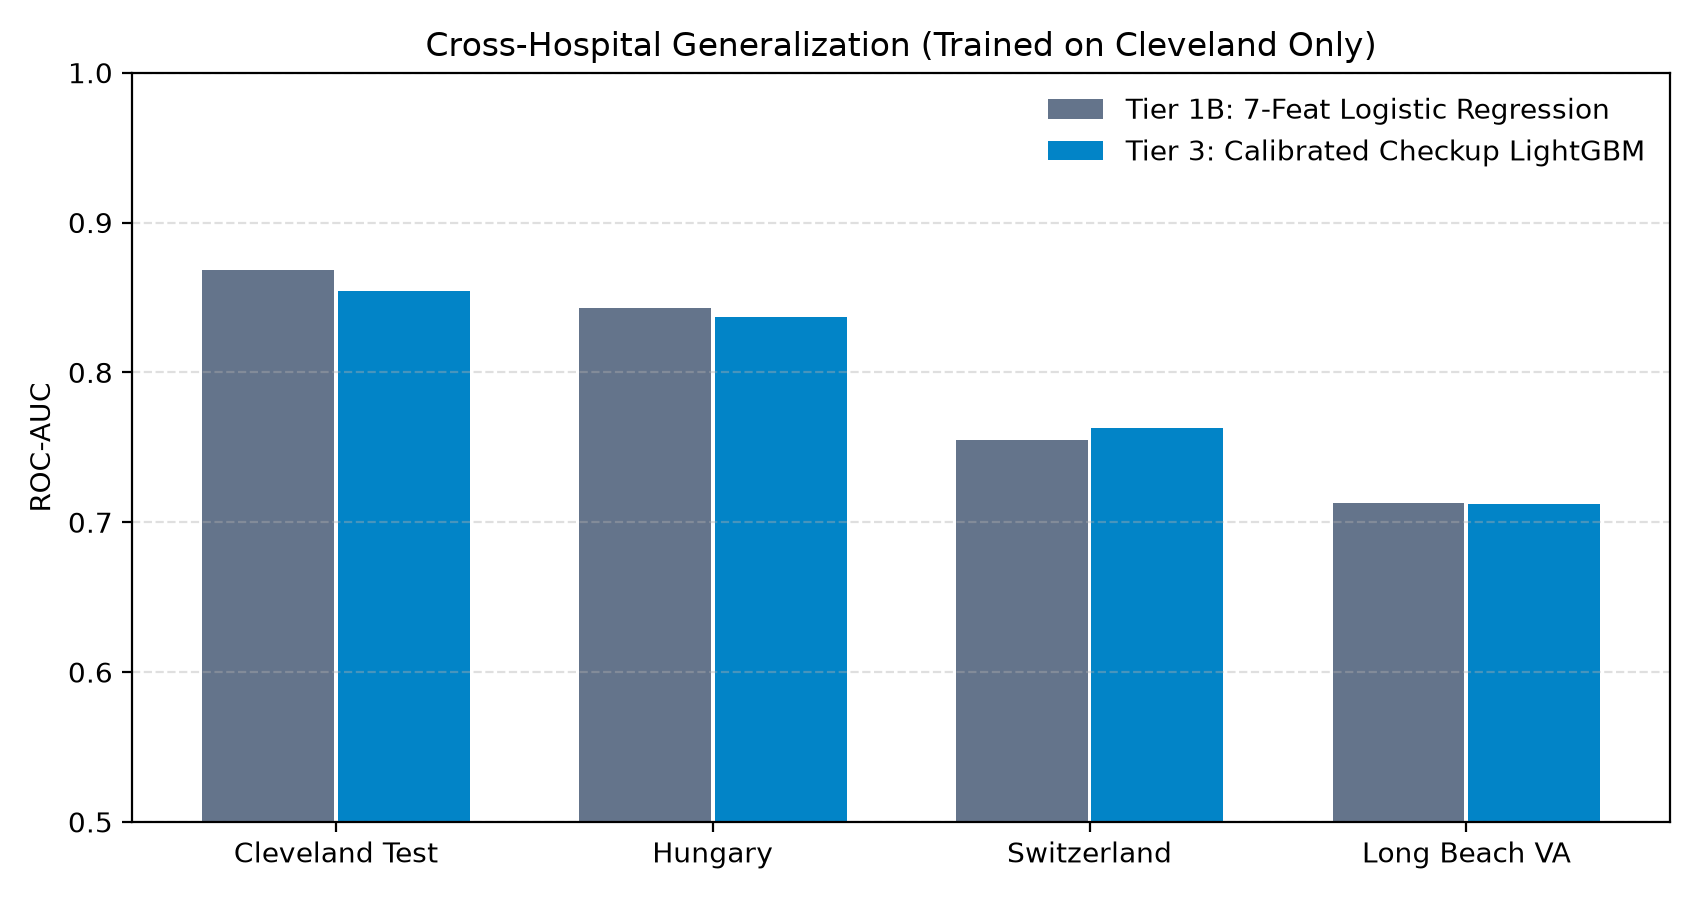

In [3]:
print('=== TIER 3 CALIBRATED CHECKUP MODEL, ABSTENTION & SITE RECALIBRATION ===')
display(pd.read_csv('artifacts/tier3_calibrated_and_recalibrated.csv'))
display(Image('artifacts/fig1_cross_hospital_drop.png'))

=== 95% BOOTSTRAP CONFIDENCE INTERVALS & SEX/AGE SUBGROUP FAIRNESS AUDIT ===


,Cohort,N,Accuracy (95% CI),Sensitivity (95% CI),Specificity (95% CI),ROC-AUC (95% CI),PR-AUC (95% CI),Brier (95% CI)
0,Cleveland Test (Holdout),61,"0.787 [0.689, 0.885]","0.857 [0.724, 0.968]","0.727 [0.568, 0.882]","0.854 [0.744, 0.952]","0.767 [0.611, 0.939]","0.155 [0.110, 0.205]"
1,Hungary (Unseen),294,"0.762 [0.714, 0.806]","0.792 [0.702, 0.864]","0.745 [0.684, 0.803]","0.837 [0.791, 0.882]","0.717 [0.626, 0.809]","0.156 [0.135, 0.177]"
2,Switzerland (Unseen),123,"0.878 [0.813, 0.935]","0.904 [0.846, 0.956]","0.500 [0.111, 0.889]","0.763 [0.528, 0.928]","0.974 [0.934, 0.997]","0.151 [0.125, 0.180]"
3,Long Beach VA (Unseen),200,"0.750 [0.685, 0.805]","0.893 [0.839, 0.937]","0.333 [0.205, 0.455]","0.712 [0.616, 0.796]","0.855 [0.787, 0.915]","0.187 [0.163, 0.212]"
4,All Unseen Hospitals Combined,617,"0.781 [0.747, 0.814]","0.868 [0.834, 0.902]","0.652 [0.593, 0.709]","0.839 [0.807, 0.872]","0.859 [0.818, 0.898]","0.165 [0.150, 0.179]"


,Subgroup,N,Prevalence,Sensitivity (Recall),Specificity,Missed Cases (FN),False Alarms (FP),ROC-AUC,Caught by Unsure Zone
0,Sex: Female (sex=0),117,0.274,0.406,0.976,19,2,0.857,12
1,Sex: Male (sex=1),561,0.652,0.907,0.523,34,93,0.810,22
2,Age: < 55 years,357,0.448,0.775,0.802,36,39,0.848,19
3,Age: >= 55 years,321,0.741,0.929,0.325,17,56,0.751,15


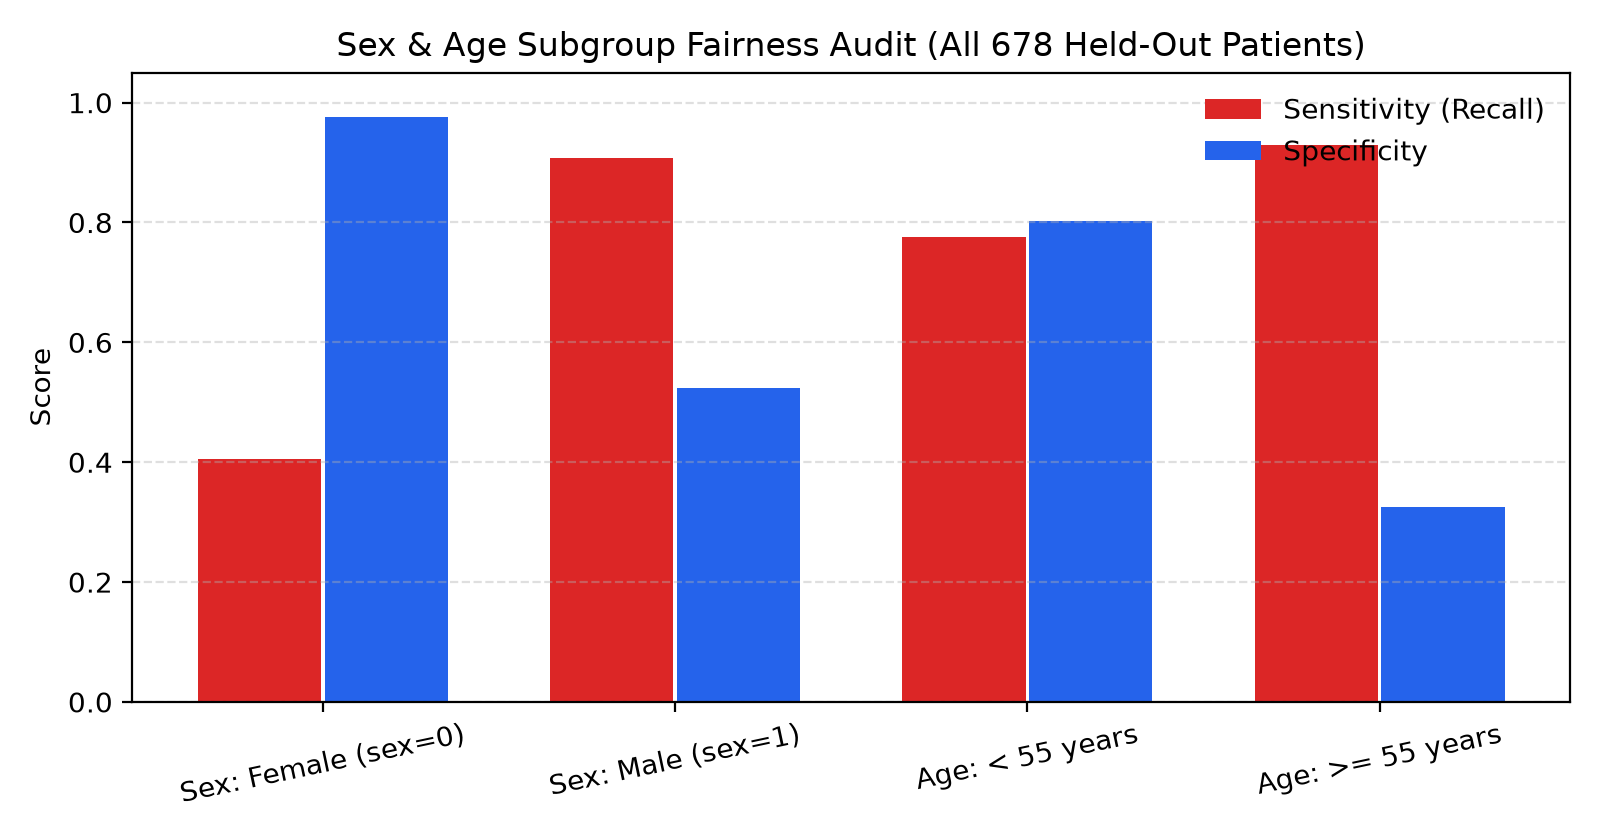

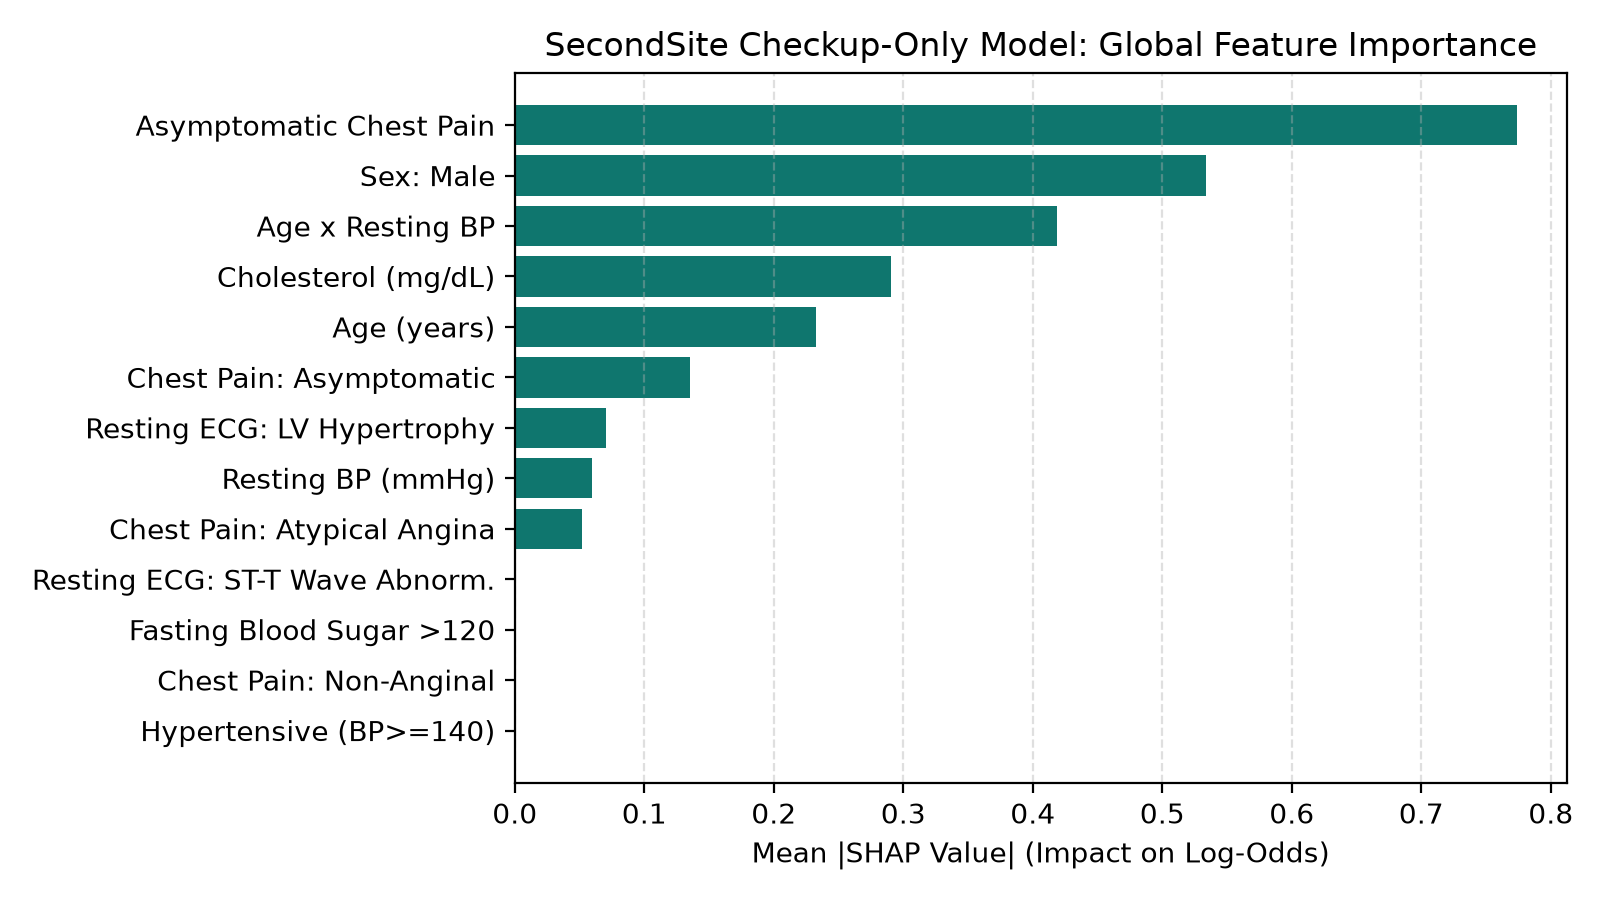

In [4]:
print('=== 95% BOOTSTRAP CONFIDENCE INTERVALS & SEX/AGE SUBGROUP FAIRNESS AUDIT ===')
display(pd.read_csv('artifacts/bootstrap_ci_summary.csv'))
display(pd.read_csv('artifacts/subgroup_fairness_audit.csv'))
display(Image('artifacts/fig2_subgroup_fairness.png'))
display(Image('artifacts/fig3_shap_summary.png'))